# VT - Vanguard Total World Stock ETF

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis
from scipy.stats import shapiro, kstest
from scipy.stats import ttest_ind
from scipy.stats import f_oneway
from scipy.stats import chi2_contingency
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

%matplotlib inline

C:\Users\niush\AppData\Roaming\Python\Python310\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# Path to the VT data file
file_path = "vt.us.txt"

# Load the file
df = pd.read_csv(file_path, delimiter=',')

In [3]:
file_path = "VT_categorized_data.csv"

categorized_df = pd.read_csv(file_path, delimiter=',')

#### Descriptive statistics

In [4]:
df.describe()

,Open,High,Low,Close,Volume,OpenInt
count,2362.000000,2362.000000,2362.000000,2362.000000,2.362000e+03,2362.0
mean,47.533031,47.755513,47.217470,47.504003,3.850259e+05,0.0
std,11.246561,11.195553,11.347279,11.277323,5.048136e+05,0.0
min,21.400000,21.583000,21.047000,21.169000,1.032700e+04,0.0
25%,38.736250,38.968250,38.384000,38.678000,1.168558e+05,0.0
50%,46.360000,46.504500,46.103000,46.279500,2.355610e+05,0.0
75%,56.824000,56.995500,56.629750,56.815250,4.583815e+05,0.0
max,72.710000,72.755000,72.490000,72.710000,6.466070e+06,0.0


In [5]:
categorized_df.describe()

,Open,High,Low,Close,Volume
count,2124.000000,2124.000000,2124.000000,2124.000000,2.124000e+03
mean,47.550385,47.772630,47.243961,47.527982,3.118559e+05
std,11.230562,11.174943,11.338202,11.262968,2.351025e+05
min,21.400000,21.583000,21.047000,21.169000,5.323400e+04
25%,38.708750,38.939750,38.382750,38.668000,1.270285e+05
50%,46.549000,46.675500,46.277000,46.480000,2.355610e+05
75%,56.900250,57.091750,56.688500,56.902250,4.269672e+05
max,72.550000,72.720000,72.440000,72.710000,1.150347e+06


#### Skewness and elongation analysis

In [6]:
# We are only calculating the “Skewness” and “Kurtosis” for “Volume” as before and after
# cause that’s the only column that we have changed 

print("Volume before:")
print(f"Volume Skewness: {skew(df['Volume'])}")    
print(f"Volume Kurtosis: {kurtosis(df['Volume'])}")

Volume before:
Volume Skewness: 4.918692178249707
Volume Kurtosis: 37.02022364276286


In [7]:
print("Dataset after:\n")

columns_to_check = ['Open', 'Close', 'High', 'Low', 'Volume']

for column in columns_to_check:
    print(f"{column} Skewness: {skew(categorized_df[column])}")
    print(f"{column} Kurtosis: {kurtosis(categorized_df[column])}\n")

Dataset after:

Open Skewness: 0.0028617526910957336
Open Kurtosis: -0.7891364086595876

Close Skewness: -0.0006399030790600112
Close Kurtosis: -0.7852574447230318

High Skewness: 0.011216570081107102
High Kurtosis: -0.8022329319548236

Low Skewness: -0.01317891121507037
Low Kurtosis: -0.7728583274048244

Volume Skewness: 1.2300747341788856
Volume Kurtosis: 0.9713051788204274



#### Statistical hypothesis testing

In [8]:
# To check whether the data follows a normal distribution (Shapiro-Wilk), (nKolmogorov)
stat, p = shapiro(categorized_df['Close'])
print(f"Shapiro-Wilk Test: \nStatistic = {stat} \np-value = {p}")

stat, p = kstest(categorized_df['Close'], 'norm')
print(f"\nKolmogorov-Smirnov Test: \nStatistic = {stat} \np-value = {p}")


# Checking if the average of two columns is different (T-test)
t_stat, p_val = ttest_ind(categorized_df['Open'], categorized_df['Close'])
print(f"\nT-Test: \nStatistic = {t_stat} \np-value = {p_val}")


# Checking the mean difference between multiple columns (Anova)
f_stat, p_val = f_oneway(categorized_df['Open'], categorized_df['Close'], categorized_df['High'])
print(f"\nANOVA Test: \nStatistic = {f_stat} \np-value = {p_val}")


# Checking the independence or relationship between two categorical columns (Chi-Square)
contingency_table = pd.crosstab(categorized_df['High_category'], categorized_df['Volume_category'])
chi2, p_val, dof, expected = chi2_contingency(contingency_table)
print(f"\nChi-Square Test: \nStatistic = {chi2} \np-value = {p_val}")

Shapiro-Wilk Test: 
Statistic = 0.9731544997946867 
p-value = 1.5956360996897213e-19

Kolmogorov-Smirnov Test: 
Statistic = 1.0 
p-value = 0.0

T-Test: 
Statistic = 0.06491433474935247 
p-value = 0.9482452630872966

ANOVA Test: 
Statistic = 0.30845418293078974 
p-value = 0.73459258080267

Chi-Square Test: 
Statistic = 6011.958046024513 
p-value = 4.508268088394311e-53


#### Correlation Analysis

Calculating Pearson and Spearman correlation coefficients

In [9]:
# Pearson correlation
pearson_corr, p_val = pearsonr(categorized_df['Low'], categorized_df['Volume'])
print(f"Pearson Correlation: \nCorrelation = {pearson_corr} \np-value = {p_val}")

# Spearman correlation
spearman_corr, p_val = spearmanr(categorized_df['Low'], categorized_df['Volume'])
print(f"\nSpearman Correlation: \nCorrelation = {spearman_corr} \np-value = {p_val}")


Pearson Correlation: 
Correlation = 0.5748727899095751 
p-value = 4.1166190597638723e-187

Spearman Correlation: 
Correlation = 0.6385902183138108 
p-value = 1.0566815383884466e-243


In [10]:
# Calculating the correlation matrix
correlation_matrix = categorized_df[['Open', 'Low', 'High', 'Close', 'Volume']].corr(method='pearson')
correlation_matrix

,Open,Low,High,Close,Volume
Open,1.000000,0.999518,0.999743,0.999347,0.578626
Low,0.999518,1.000000,0.999399,0.999652,0.574873
High,0.999743,0.999399,1.000000,0.999612,0.580403
Close,0.999347,0.999652,0.999612,1.000000,0.576728
Volume,0.578626,0.574873,0.580403,0.576728,1.000000


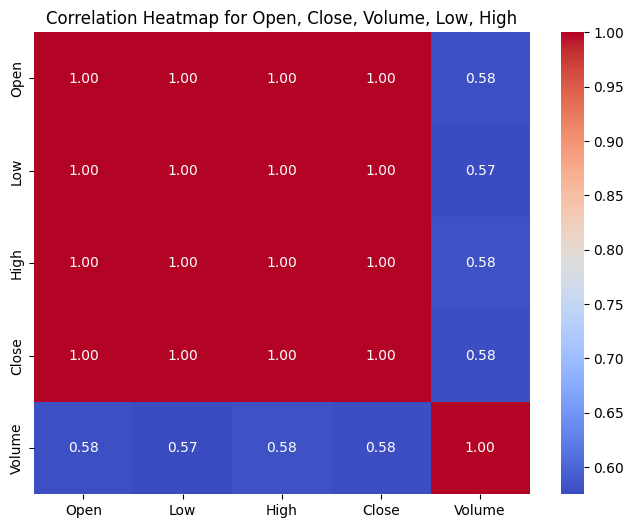

In [11]:
# drawing for heatmap matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Heatmap for Open, Close, Volume, Low, High")
plt.show()


In [12]:
# extracting strong correlations
strong_correlations = correlation_matrix[(correlation_matrix > 0.7) | (correlation_matrix < -0.7)]
print("Strong Correlations:")
print(strong_correlations)


Strong Correlations:
            Open       Low      High     Close  Volume
Open    1.000000  0.999518  0.999743  0.999347     NaN
Low     0.999518  1.000000  0.999399  0.999652     NaN
High    0.999743  0.999399  1.000000  0.999612     NaN
Close   0.999347  0.999652  0.999612  1.000000     NaN
Volume       NaN       NaN       NaN       NaN     1.0


#### Dispersion Analysis

In [13]:
dispersion = categorized_df['Volume'].var() / categorized_df['Volume'].mean()
print(f"Dispersion Ratio: {dispersion}")


Dispersion Ratio: 177239.54772199373


#### Multicollinearity Analysis

In [14]:
X = categorized_df[['Open', 'High', 'Low', 'Close', 'Volume']]
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data)


  feature           VIF
0    Open  63835.037518
1    High  72404.077073
2     Low  43359.736669
3   Close  58191.923677
4  Volume      3.781715


#### Comparative Analysis

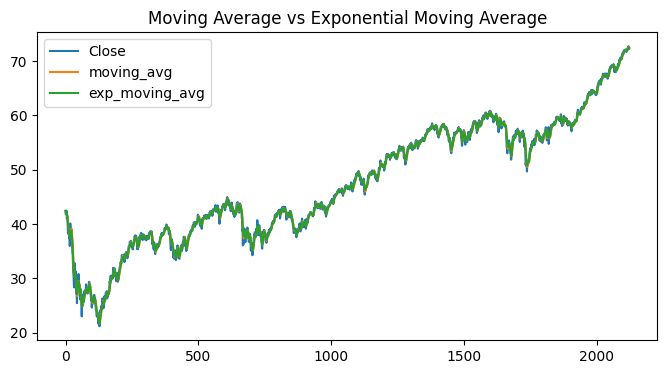

In [15]:
categorized_df['moving_avg'] = categorized_df['Close'].rolling(window=5).mean()
categorized_df['exp_moving_avg'] = categorized_df['Close'].ewm(span=5).mean()

categorized_df[['Close', 'moving_avg', 'exp_moving_avg']].plot(figsize=(8, 4))
plt.title("Moving Average vs Exponential Moving Average")
plt.show()


#### Statistical Regression Analysis

In [16]:
X = categorized_df[['Open', 'High', 'Low']]
y = categorized_df['Close']
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                  Close   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 2.181e+06
Date:                Sat, 23 Nov 2024   Prob (F-statistic):               0.00
Time:                        04:50:05   Log-Likelihood:                 376.65
No. Observations:                2124   AIC:                            -745.3
Df Residuals:                    2120   BIC:                            -722.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0085      0.024     -0.362      0.7

#### Drawing a scatter plot with a regression line

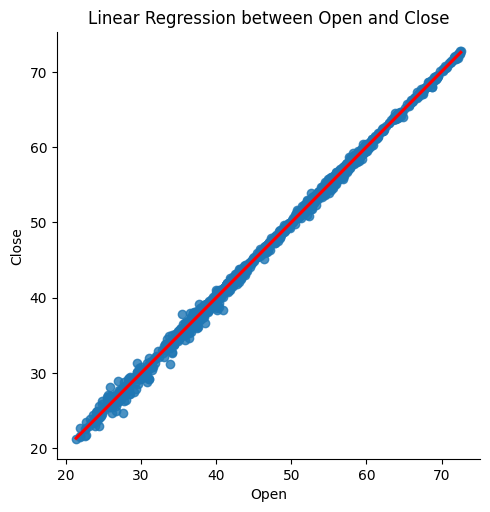

In [17]:
sns.lmplot(x='Open', y='Close', data=categorized_df, line_kws={'color': 'red'})
plt.title("Linear Regression between Open and Close")
plt.show()
